# E-Commerce Sales & Customer Behavior Analytics

### SQL, Python & Business Insights


## Dataset and analysis scope

Seven supplied CSV tables are used: `customers`, `orders`, `order_items`,
`payments`, `products`, `sellers`, and `geolocation`. They represent a Brazilian
e-commerce dataset. The exact original source and reuse license should be
verified and credited before public publication.

**Financial metric definitions:** Product sales = sum of `order_items.price`
(excludes freight). Payment value = sum of `payments.payment_value`
(may include freight or other payment components). Neither is net profit.

**Coverage limitation:** 2016 records are partial. In 2018, only 20 orders are
recorded in September–October and none afterward; therefore, year comparisons
use January–August 2017 versus January–August 2018.

**Safety:** These notebooks only read from the already-imported `ecommerce`
database. The separate import script is intentionally guarded against
re-importing existing tables. Keep database credentials out of GitHub.


## 1. Environment Setup

Run this on a machine with the already-imported MySQL database.


In [ ]:
import os
from getpass import getpass

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mysql.connector

# Environment variables are optional; no secrets are stored in the notebook.
db = mysql.connector.connect(
    host=os.getenv("MYSQL_HOST", "localhost"),
    user=os.getenv("MYSQL_USER", "root"),
    password=os.getenv("MYSQL_PASSWORD") or getpass("MySQL password: "),
    database=os.getenv("MYSQL_DATABASE", "ecommerce"),
)
cur = db.cursor()
print("Connected to MySQL database:", db.database)


## 2. SQL + Python Business Analysis

Each question combines a business objective, a MySQL query executed through
Python, relevant visualization, and an interpretation. The figures below are
the original saved outputs from the user's successful local runs; rerunning
the notebook requires a local MySQL database with the supplied CSV tables.


### Q1. List All Unique Cities Where Customers Are Located

**Objective:** Identify the geographical distribution of customers.

**SQL Concepts:** SELECT, DISTINCT, ORDER BY

In [ ]:
query = """
SELECT DISTINCT customer_city
FROM customers
ORDER BY customer_city;
"""

cur.execute(query)

data = cur.fetchall()

df = pd.DataFrame(data, columns=["Customer City"])

display(df.head(10))

print("Total unique cities:", len(df))

,Customer City
0,abadia dos dourados
1,abadiania
2,abaete
3,abaetetuba
4,abaiara
5,abaira
6,abare
7,abatia
8,abdon batista
9,abelardo luz


Total unique cities: 4119


**Result:** 4,119 distinct customer cities.

**Interpretation:** The records cover many locations, although the number of
distinct city labels alone does not establish equal market penetration across
cities or unique customer counts.


### Q2. Orders Placed in 2017

**Objective:** Count recorded orders purchased during calendar year 2017.

**SQL concepts:** `COUNT`, `WHERE`, `YEAR`.

**Business relevance:** Provides a baseline for later order-volume comparisons.


In [ ]:
query = """
SELECT COUNT(order_id) AS total_orders_2017
FROM orders
WHERE YEAR(order_purchase_timestamp) = 2017;
"""

cur.execute(query)

data = cur.fetchone()

total_orders = data[0]

print(f"Total orders placed in 2017: {total_orders:,}")

Total orders placed in 2017: 45,101


**Result:** A total of 45,101 orders were placed in 2017.

**Business Insight:** The e-commerce platform recorded 45,101 orders during 2017. This establishes a baseline for evaluating order growth and sales performance in subsequent years.

### Q3. Calculate Total Sales by Product Category

**Objective:** Analyze sales performance across different product categories to identify which categories generate the highest sales.

**SQL Concepts:** JOIN, GROUP BY, SUM(), ROUND(), ORDER BY

**Business Relevance:** Category-level sales analysis helps businesses identify their strongest product segments and make better inventory and marketing decisions.

In [ ]:
#Total Product Sales by Category

query = """
SELECT
    UPPER(p.product_category) AS category,
    ROUND(SUM(oi.price), 2) AS total_sales
FROM products AS p
JOIN order_items AS oi
    ON p.product_id = oi.product_id
GROUP BY p.product_category
ORDER BY total_sales DESC;
"""

cur.execute(query)

data = cur.fetchall()

df_sales = pd.DataFrame(
    data,
    columns=["Category", "Total Sales"]
)

display(df_sales.head(10))

,Category,Total Sales
0,HEALTH BEAUTY,1258681.34
1,WATCHES PRESENT,1205005.68
2,BED TABLE BATH,1036988.68
3,SPORT LEISURE,988048.97
4,COMPUTER ACCESSORIES,911954.32
5,FURNITURE DECORATION,729762.49
6,COOL STUFF,635290.85
7,HOUSEWARES,632248.66
8,AUTOMOTIVE,592720.11
9,GARDEN TOOLS,485256.46


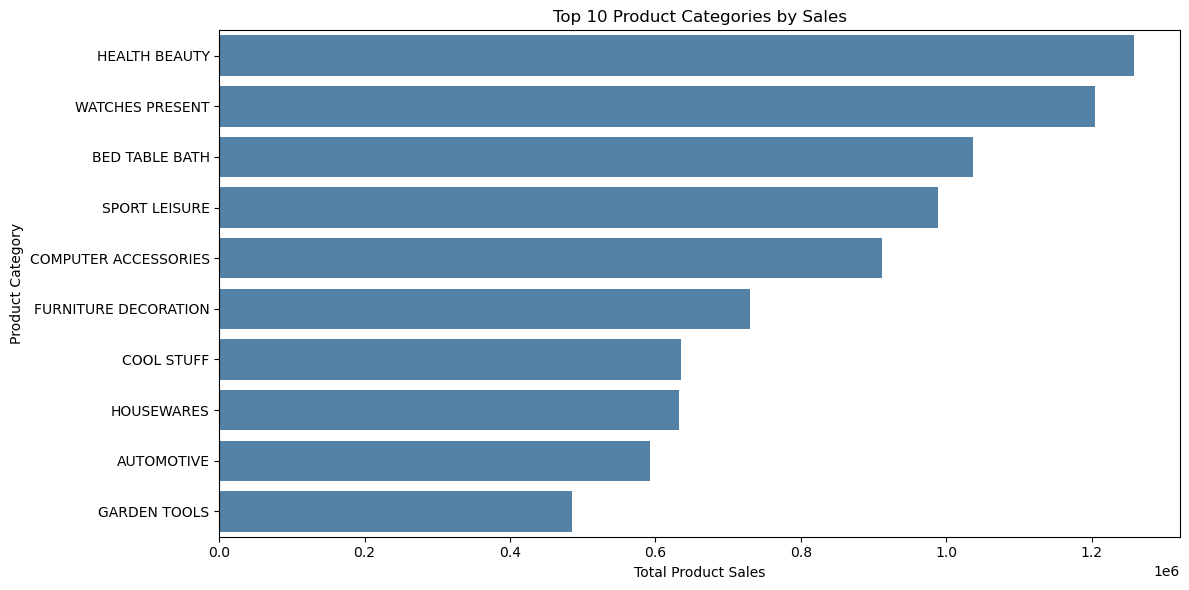

In [ ]:
# Top 10 Product Categories by Sales

top_10 = df_sales.head(10).copy()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10,
    x="Total Sales",
    y="Category",
    color="steelblue"
)

plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Total Product Sales")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

**Results:**

The three highest-performing product categories by item sales value were:

1. Health Beauty — BRL 1,258,681.34
2. Watches Present — BRL 1,205,005.68
3. Bed Table Bath — BRL 1,036,988.68

**Business Insights:**

- Health Beauty generated the highest product sales value among all categories.
- Watches Present and Bed Table Bath ranked second and third, respectively.
- These categories represent important contributors to product sales performance.

**Business Recommendation:**

The company could investigate customer demand, inventory availability, and profit margins in these high-performing categories before making inventory or marketing investment decisions.

**Note:** Sales values are calculated using item prices and exclude freight charges. They should not be interpreted as net profit.

### Q4. Calculate the Percentage of Orders Paid in Installments

**Objective:** Determine the percentage of orders that were paid using multiple installments.

**SQL Concepts:** COUNT(), DISTINCT, CASE WHEN, ROUND(), NULLIF()

**Business Relevance:** Understanding installment payment behavior helps businesses analyze customer payment preferences and financial flexibility.

**Methodology:** Orders with more than one installment are classified as installment-based orders. Each order is counted only once, even if it has multiple payment records.

In [ ]:
# Percentage of Orders Paid in Installments

query = """
SELECT
    COUNT(DISTINCT order_id) AS total_orders,

    COUNT(DISTINCT CASE
        WHEN payment_installments > 1 THEN order_id
    END) AS installment_orders,

    ROUND(
        COUNT(DISTINCT CASE
            WHEN payment_installments > 1 THEN order_id
        END) * 100.0
        / NULLIF(COUNT(DISTINCT order_id), 0),
        2
    ) AS installment_percentage

FROM payments;
"""

cur.execute(query)

data = cur.fetchone()

total_orders = data[0]
installment_orders = data[1]
installment_percentage = data[2]

print(f"Total Orders with Payment Records: {total_orders:,}")
print(f"Orders Paid in Installments: {installment_orders:,}")
print(f"Percentage Paid in Installments: {installment_percentage}%")

Total Orders with Payment Records: 99,440
Orders Paid in Installments: 51,170
Percentage Paid in Installments: 51.46%


**Results:**

- Total Orders with Payment Records: 99,440
- Orders Paid in Multiple Installments: 51,170
- Percentage of Orders Paid in Installments: 51.46%

**Business Insights:**

- Approximately 51.46% of orders with recorded payments were paid using multiple installments.
- More than half of the orders with payment records involved installment-based payments, suggesting that payment flexibility is important to many customers.
- The remaining 48.54% of orders did not have a recorded payment with more than one installment.

**Business Recommendation:**

The business should continue evaluating installment payment options as part of its checkout strategy. Further analysis of payment methods, order values, and customer preferences could help determine their impact on purchasing behavior.

**Note:** This analysis counts each order once and classifies an order as installment-based if at least one of its payment records has more than one installment.

### Q5. Count the Number of Customers from Each State

**Objective:** Analyze the geographical distribution of customers across different states.

**SQL Concepts:** SELECT, COUNT(), GROUP BY, ORDER BY

**Business Relevance:** Understanding customer distribution helps identify key geographical markets and supports region-specific marketing and logistics decisions.

In [ ]:
# Customer Distribution by State

query = """
SELECT
    customer_state AS state,
    COUNT(customer_id) AS customer_count
FROM customers
GROUP BY customer_state
ORDER BY customer_count DESC;
"""

cur.execute(query)

data = cur.fetchall()

df_states = pd.DataFrame(
    data,
    columns=["State", "Customer Count"]
)

display(df_states.head(10))

print("Total States:", len(df_states))

,State,Customer Count
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


Total States: 27


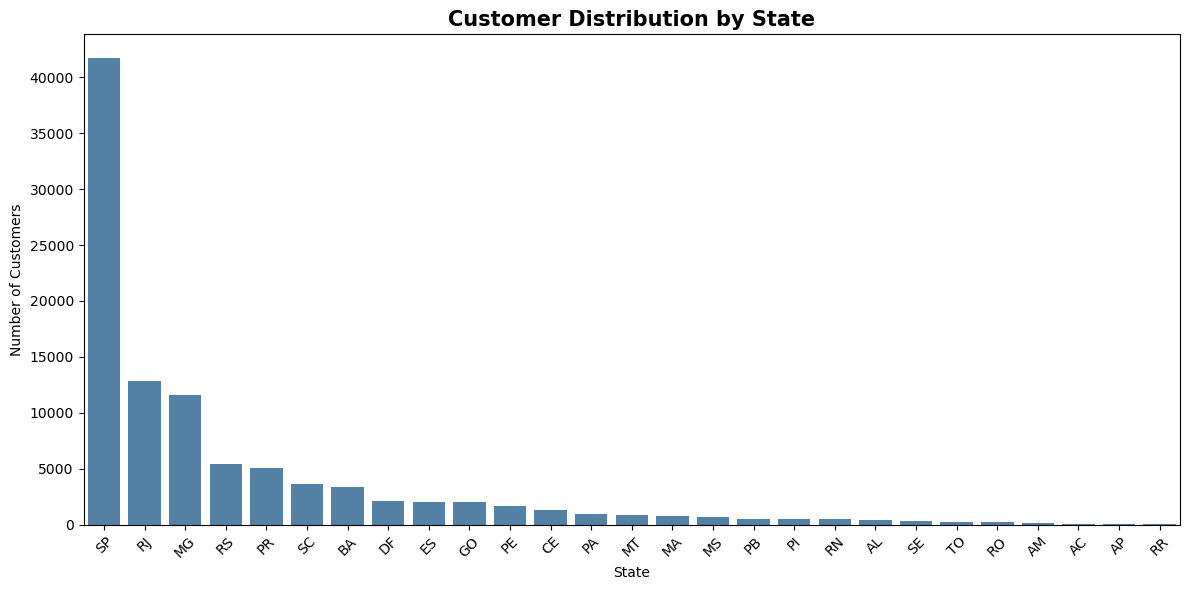

In [ ]:
# Visualizing Customers by State

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_states,
    x="State",
    y="Customer Count",
    color="steelblue"
)

plt.title(
    "Customer Distribution by State",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("State")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Results:**

- Total States Represented: 27
- São Paulo (SP): 41,746 customer records
- Rio de Janeiro (RJ): 12,852 customer records
- Minas Gerais (MG): 11,635 customer records

**Business Insights:**

- São Paulo has the highest customer concentration, representing approximately 42% of all customer records.
- Rio de Janeiro and Minas Gerais rank second and third.
- Together, these three states account for approximately 66.6% of customer records.
- Customer distribution is highly concentrated in a few geographical markets.

**Business Recommendations:**

- Investigate opportunities to strengthen delivery operations in high-demand states.
- Explore marketing opportunities in states with lower customer representation.
- Analyze sales and customer purchasing behavior by region to guide expansion decisions.

**Note:** This analysis counts customer records rather than necessarily unique individuals.

### Q6. Calculate the Number of Orders per Month in 2018

**Objective:** Analyze monthly order volumes during 2018 to identify changes in customer purchasing activity over time.

**SQL Concepts:** COUNT(), YEAR(), MONTH(), GROUP BY, ORDER BY

**Business Relevance:** Monthly order trends help businesses understand changes in demand, identify peak periods, and make informed inventory and operational decisions.

In [ ]:
# Monthly Orders in 2018

query = """
SELECT
    MONTH(order_purchase_timestamp) AS month_number,
    COUNT(order_id) AS order_count
FROM orders
WHERE YEAR(order_purchase_timestamp) = 2018
GROUP BY MONTH(order_purchase_timestamp)
ORDER BY month_number;
"""

cur.execute(query)

data = cur.fetchall()

df_monthly = pd.DataFrame(
    data,
    columns=["Month Number", "Order Count"]
)

# Convert month numbers to names
import calendar

df_monthly["Month"] = df_monthly["Month Number"].apply(
    lambda x: calendar.month_name[x]
)

display(df_monthly[["Month", "Order Count"]])

,Month,Order Count
0,January,7269
1,February,6728
2,March,7211
3,April,6939
4,May,6873
5,June,6167
6,July,6292
7,August,6512
8,September,16
9,October,4


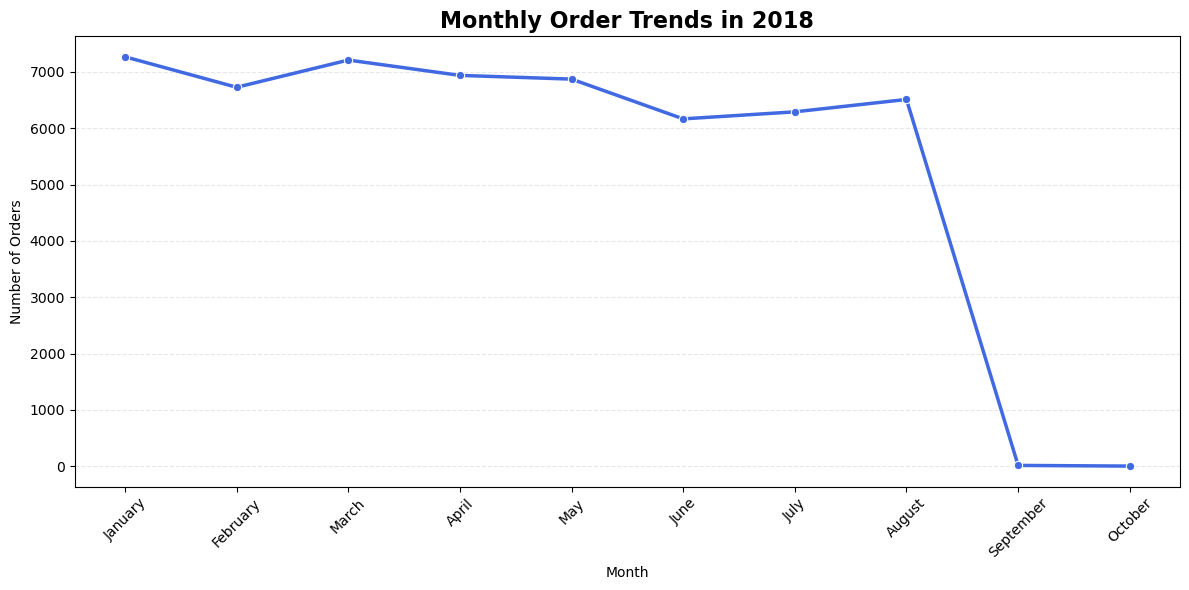

In [ ]:
# Q6 Visualization: Monthly Order Trends

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_monthly,
    x="Month",
    y="Order Count",
    marker="o",
    linewidth=2.5,
    color="royalblue"
)

plt.title(
    "Monthly Order Trends in 2018",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Check date coverage of the dataset

query = """
SELECT
    MIN(order_purchase_timestamp) AS first_order_date,
    MAX(order_purchase_timestamp) AS last_order_date,
    COUNT(*) AS total_orders
FROM orders
WHERE YEAR(order_purchase_timestamp) = 2018;
"""

cur.execute(query)

data = cur.fetchone()

print("First Order Date:", data[0])
print("Last Order Date:", data[1])
print("Total Orders in 2018:", data[2])

First Order Date: 2018-01-01 02:48:41
Last Order Date: 2018-10-17 17:30:18
Total Orders in 2018: 54011


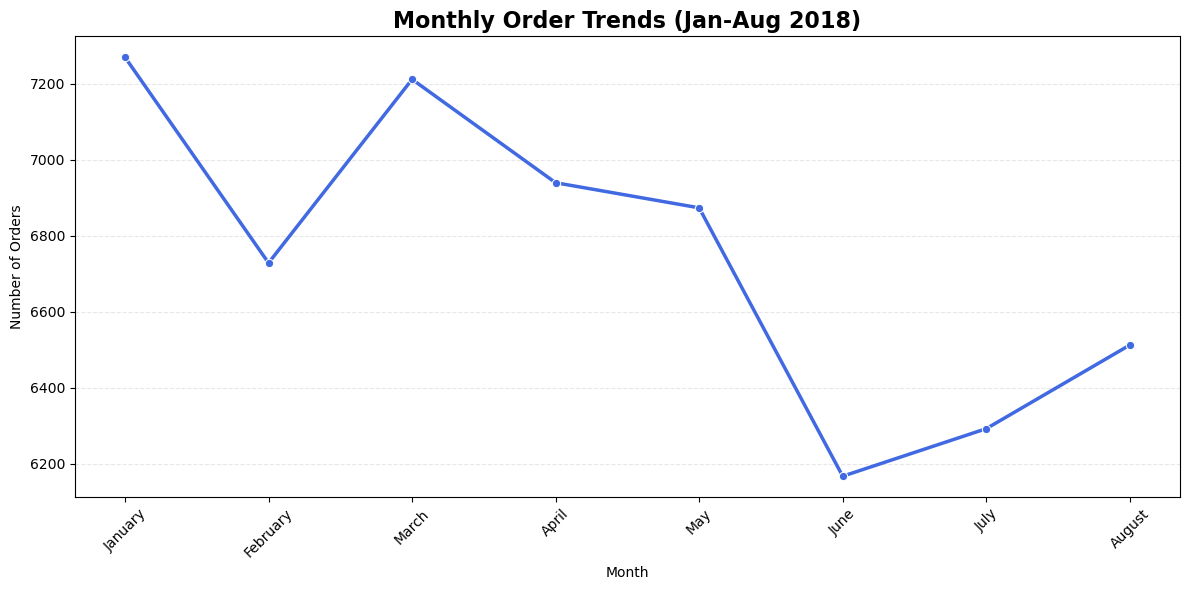

In [ ]:
# Monthly Order Trends (January - August 2018)

df_monthly_complete = df_monthly[
    df_monthly["Month Number"].between(1, 8)
].copy()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_monthly_complete,
    x="Month",
    y="Order Count",
    marker="o",
    linewidth=2.5,
    color="royalblue"
)

plt.title(
    "Monthly Order Trends (Jan-Aug 2018)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

**Data Coverage Verification:**

- First Recorded Order in 2018: January 1, 2018
- Last Recorded Order in 2018: October 17, 2018
- Total Orders in 2018: 54,011
- Orders from January to August: 53,991
- Orders from September to October: 20

**Conclusion:**

Approximately 99.96% of recorded 2018 orders occurred between January and August.

Monthly order volumes remained relatively stable during January–August, ranging from 6,167 to 7,269 orders.

September and October contain unusually few records. Therefore, these months were excluded from the focused trend visualization to avoid misleading interpretations.

**Limitation:** The available records do not establish whether the sharp decline reflects incomplete data collection or actual business activity.

### Q7. Calculate the Average Number of Products per Order by Customer City

**Objective:** Determine the average number of products purchased per order in each customer city.

**SQL Concepts:** JOIN, COUNT(), AVG(), GROUP BY, HAVING, CTE, ORDER BY

**Business Relevance:** Understanding average basket size across cities helps identify purchasing patterns and supports regional marketing strategies.

**Methodology:** First, the number of products in each order is calculated. Then, the average number of products per order is determined for each customer city.

In [ ]:
# Average Products per Order by Customer City

query = """
WITH products_per_order AS (
    SELECT
        o.order_id,
        o.customer_id,
        COUNT(oi.order_id) AS product_count
    FROM orders AS o
    JOIN order_items AS oi
        ON o.order_id = oi.order_id
    GROUP BY
        o.order_id,
        o.customer_id
)

SELECT
    c.customer_city AS city,
    COUNT(*) AS total_orders,
    ROUND(AVG(p.product_count), 2) AS avg_products_per_order
FROM customers AS c
JOIN products_per_order AS p
    ON c.customer_id = p.customer_id
GROUP BY c.customer_city
ORDER BY avg_products_per_order DESC;
"""

cur.execute(query)

data = cur.fetchall()

df_city_products = pd.DataFrame(
    data,
    columns=[
        "City",
        "Total Orders",
        "Average Products per Order"
    ]
)

display(df_city_products.head(10))

,City,Total Orders,Average Products per Order
0,padre carvalho,1,7.00
1,celso ramos,2,6.50
2,datas,1,6.00
3,candido godoi,1,6.00
4,matias olimpio,1,5.00
5,cidelandia,1,4.00
6,picarra,1,4.00
7,morro de sao paulo,1,4.00
8,teixeira soares,1,4.00
9,curralinho,1,4.00


In [ ]:
#  Top Cities with at Least 10 Orders

df_reliable_cities = df_city_products[
    df_city_products["Total Orders"] >= 10
].copy()

df_reliable_cities = df_reliable_cities.sort_values(
    by="Average Products per Order",
    ascending=False
)

display(df_reliable_cities.head(10))

,City,Total Orders,Average Products per Order
29,cicero dantas,10,2.30
41,morro agudo,10,2.00
129,aguai,10,1.90
132,itajobi,10,1.80
136,irece,13,1.77
162,janauba,17,1.65
163,sao joao nepomuceno,14,1.64
164,uniao da vitoria,29,1.62
165,ariquemes,13,1.62
166,eusebio,13,1.62


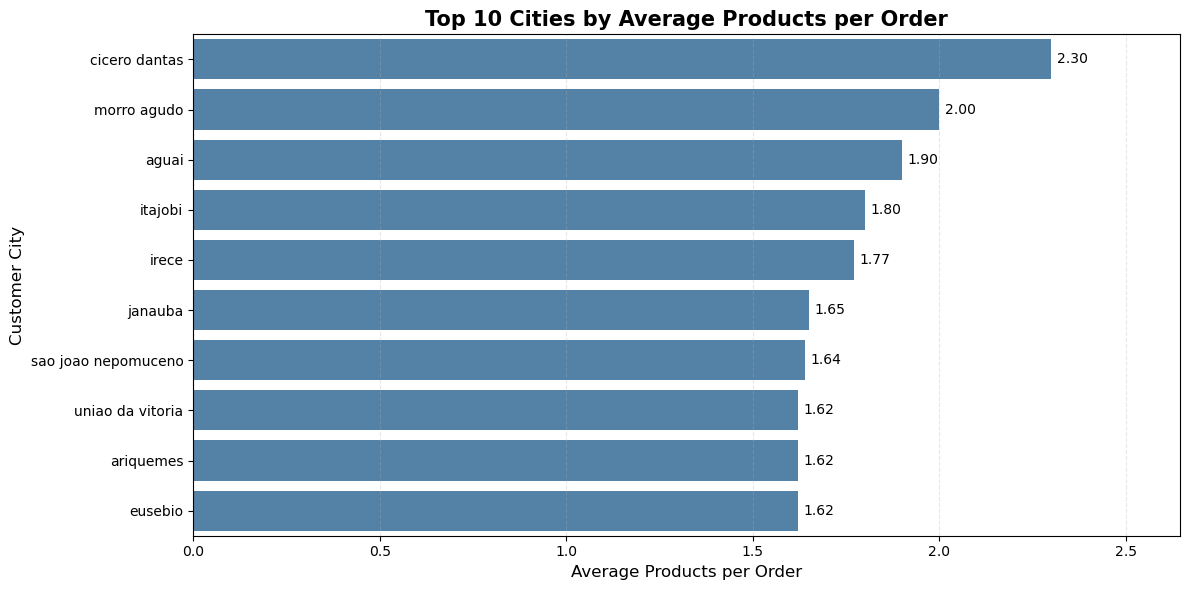

In [ ]:
# Q7 Visualization: Average Products per Order by City

# Select top 10 cities
top_10_cities = df_reliable_cities.head(10).copy()

# Convert Decimal values to float
top_10_cities["Average Products per Order"] = (
    top_10_cities["Average Products per Order"].astype(float)
)

# Set figure size
plt.figure(figsize=(12, 6))

# Create horizontal bar chart
ax = sns.barplot(
    data=top_10_cities,
    x="Average Products per Order",
    y="City",
    color="steelblue"
)

# Chart title
plt.title(
    "Top 10 Cities by Average Products per Order",
    fontsize=15,
    fontweight="bold"
)

# Axis labels
plt.xlabel("Average Products per Order", fontsize=12)
plt.ylabel("Customer City", fontsize=12)

# Display values on bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4
    )

# Set X-axis limits
max_value = top_10_cities["Average Products per Order"].max()

plt.xlim(0, max_value * 1.15)

# Improve chart appearance
plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

# Display chart
plt.show()

**Results:** Among cities with at least 10 orders containing
order items, Cicero Dantas recorded 2.30 products per order (10 orders),
Morro Agudo 2.00 (10), and Aguai 1.90 (10).

**Interpretation:** An unfiltered ranking was dominated by cities with just
one or two orders, so a minimum sample threshold improves interpretability.
The 10-order cutoff is a heuristic; these are still small samples and should
not directly drive regional marketing decisions.


### Q8. Calculate the Percentage of Total Product Sales Contributed by Each Category

**Objective:** Determine the percentage contribution of each product category to overall product sales.

**SQL Concepts:** JOIN, GROUP BY, SUM(), ROUND(), CTE, Window Functions, ORDER BY

**Business Relevance:** Understanding category-level sales contributions helps businesses identify major product segments, evaluate sales concentration, and support marketing and inventory decisions.

**Methodology:** Category-level product sales are calculated using item prices. Each category's sales are then divided by total product sales to determine its percentage contribution.

In [ ]:
# Percentage of Total Product Sales by Category

query = """
WITH category_sales AS (
    SELECT
        COALESCE(
            UPPER(p.product_category),
            'UNKNOWN'
        ) AS category,

        SUM(oi.price) AS total_sales

    FROM products AS p

    JOIN order_items AS oi
        ON p.product_id = oi.product_id

    GROUP BY
        COALESCE(UPPER(p.product_category), 'UNKNOWN')
)

SELECT
    category,

    ROUND(total_sales, 2) AS total_sales,

    ROUND(
        total_sales * 100.0 /
        NULLIF(SUM(total_sales) OVER (), 0),
        2
    ) AS sales_percentage

FROM category_sales

ORDER BY sales_percentage DESC;
"""

cur.execute(query)

data = cur.fetchall()

df_category_percentage = pd.DataFrame(
    data,
    columns=[
        "Category",
        "Total Sales",
        "Sales Percentage"
    ]
)

# Convert numeric columns for analysis and plotting
df_category_percentage["Total Sales"] = pd.to_numeric(
    df_category_percentage["Total Sales"]
)

df_category_percentage["Sales Percentage"] = pd.to_numeric(
    df_category_percentage["Sales Percentage"]
)

# Display top 10 categories
display(df_category_percentage.head(10))

# Check total percentage
print(
    "Total Percentage:",
    round(df_category_percentage["Sales Percentage"].sum(), 2),
    "%"
)

,Category,Total Sales,Sales Percentage
0,HEALTH BEAUTY,1258681.34,9.26
1,WATCHES PRESENT,1205005.68,8.87
2,BED TABLE BATH,1036988.68,7.63
3,SPORT LEISURE,988048.97,7.27
4,COMPUTER ACCESSORIES,911954.32,6.71
5,FURNITURE DECORATION,729762.49,5.37
6,COOL STUFF,635290.85,4.67
7,HOUSEWARES,632248.66,4.65
8,AUTOMOTIVE,592720.11,4.36
9,GARDEN TOOLS,485256.46,3.57


Total Percentage: 99.98 %


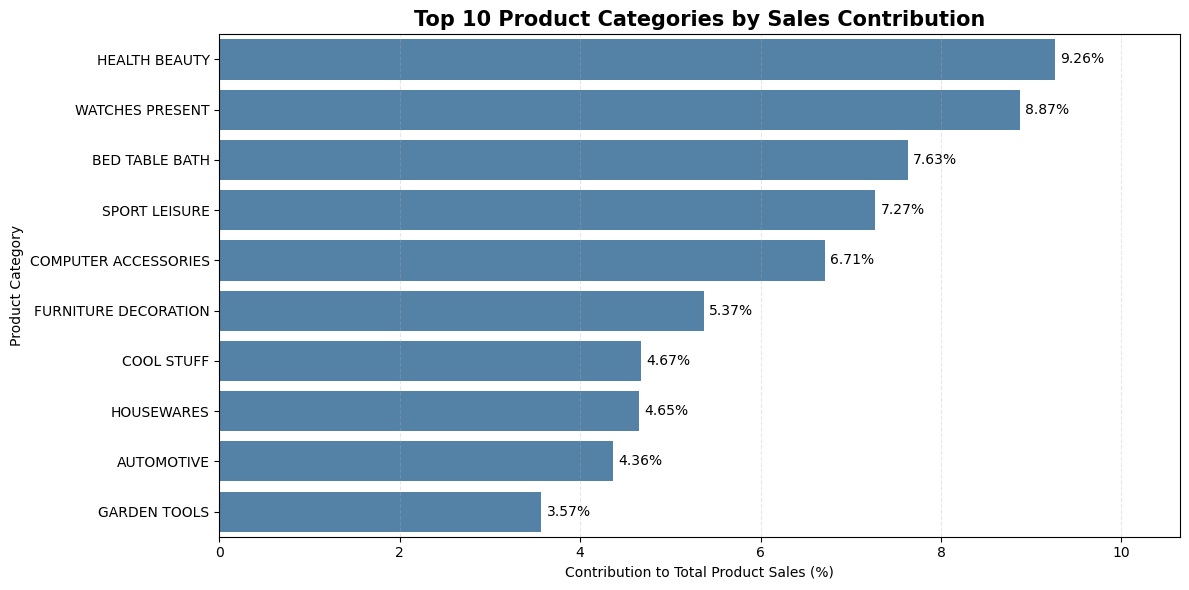

In [ ]:
# Visualization: Top 10 Product Categories by Sales Contribution

top_10_categories = df_category_percentage.head(10).copy()

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_10_categories,
    x="Sales Percentage",
    y="Category",
    color="steelblue"
)

plt.title(
    "Top 10 Product Categories by Sales Contribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Contribution to Total Product Sales (%)")
plt.ylabel("Product Category")

# Display percentages on bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=4
    )

# Set axis limits
max_percentage = top_10_categories["Sales Percentage"].max()

plt.xlim(0, max_percentage * 1.15)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

**Results:**

The top five product categories by sales contribution were:

1. Health Beauty — 9.26%
2. Watches Present — 8.87%
3. Bed Table Bath — 7.63%
4. Sport Leisure — 7.27%
5. Computer Accessories — 6.71%

**Business Insights:**

- Health Beauty contributed the largest share of total product sales at 9.26%.
- Watches Present ranked second with an 8.87% contribution.
- The top five categories collectively contributed 39.74% of product sales.
- The top ten categories accounted for approximately 62.36% of product sales.
- Sales are distributed across several categories rather than being dominated by a single category.

**Business Recommendations:**

- Monitor inventory availability and demand in high-contributing categories.
- Investigate opportunities to improve the performance of lower-contributing categories.
- Consider category profitability, customer demand, and seasonal trends before allocating marketing budgets.

**Methodology Note:**

Percentages are calculated using product item prices, excluding freight charges.

The sum of individually rounded category percentages is 99.98%, reflecting rounding differences.

### Q9. Analyze the Correlation Between Product Price and Purchase Frequency

**Objective:** Investigate whether product prices are associated with the number of units purchased.

**SQL Concepts:** JOIN, COUNT(), AVG(), GROUP BY

**Python Libraries:** Pandas, NumPy, Matplotlib, Seaborn

**Statistical Method:** Pearson Correlation Coefficient

**Business Relevance:** Understanding the relationship between product prices and purchase frequency can help identify pricing patterns and support further pricing strategy analysis.

**Methodology:** Each product's average recorded selling price is compared with the total number of times that product appears in order items.

In [ ]:
# Correlation Between Product Price and Purchase Frequency

query = """
SELECT
    oi.product_id,

    COUNT(*) AS purchase_frequency,

    ROUND(AVG(oi.price), 2) AS average_price

FROM order_items AS oi

GROUP BY oi.product_id

ORDER BY purchase_frequency DESC;
"""

cur.execute(query)

data = cur.fetchall()

df_correlation = pd.DataFrame(
    data,
    columns=[
        "Product ID",
        "Purchase Frequency",
        "Average Price"
    ]
)

# Convert to numeric types
df_correlation["Purchase Frequency"] = pd.to_numeric(
    df_correlation["Purchase Frequency"]
)

df_correlation["Average Price"] = pd.to_numeric(
    df_correlation["Average Price"]
)

# Remove incomplete records
df_correlation = df_correlation.dropna(
    subset=["Purchase Frequency", "Average Price"]
)

# Display sample
display(df_correlation.head(10))

# Calculate Pearson correlation
correlation = df_correlation[
    "Average Price"
].corr(
    df_correlation["Purchase Frequency"]
)

print(f"Pearson Correlation Coefficient: {correlation:.4f}")

print(f"Total Products Analyzed: {len(df_correlation):,}")

,Product ID,Purchase Frequency,Average Price
0,aca2eb7d00ea1a7b8ebd4e68314663af,527,71.36
1,99a4788cb24856965c36a24e339b6058,488,88.17
2,422879e10f46682990de24d770e7f83d,484,54.91
3,389d119b48cf3043d311335e499d9c6b,392,54.70
4,368c6c730842d78016ad823897a372db,388,54.27
5,53759a2ecddad2bb87a079a1f1519f73,373,54.66
6,d1c427060a0f73f6b889a5c7c61f2ac4,343,137.65
7,53b36df67ebb7c41585e8d54d6772e08,323,116.67
8,154e7e31ebfa092203795c972e5804a6,281,22.51
9,3dd2a17168ec895c781a9191c1e95ad7,274,149.94


Pearson Correlation Coefficient: -0.0321
Total Products Analyzed: 32,951


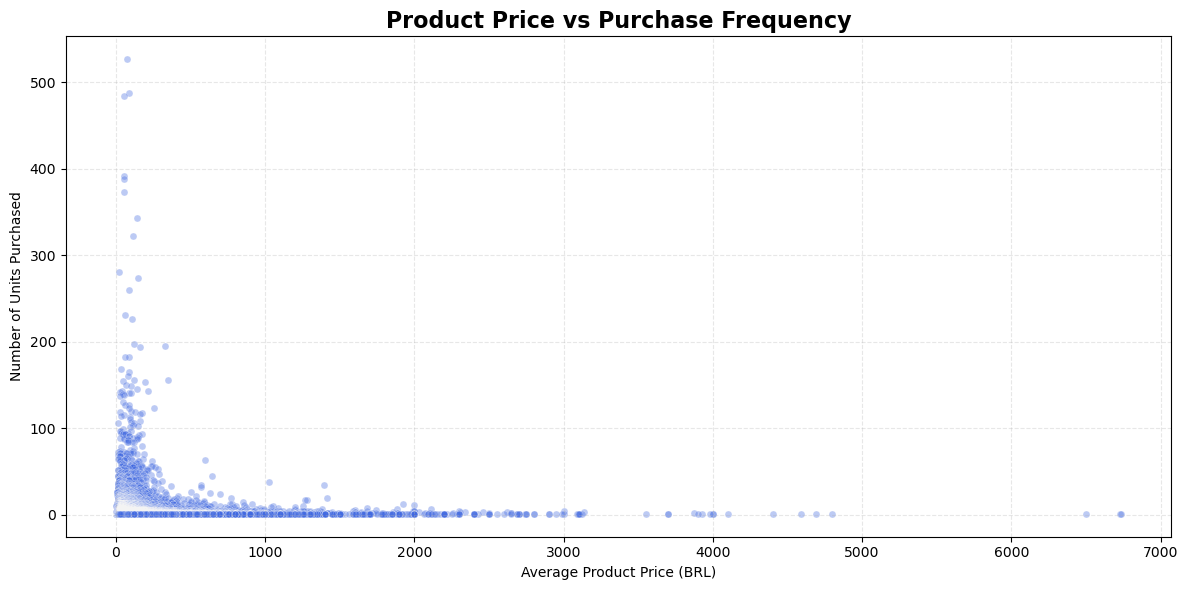

In [ ]:
# Visualization: Price vs Purchase Frequency

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df_correlation,
    x="Average Price",
    y="Purchase Frequency",
    alpha=0.35,
    color="royalblue",
    s=25
)

plt.title(
    "Product Price vs Purchase Frequency",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Average Product Price (BRL)")
plt.ylabel("Number of Units Purchased")

plt.grid(
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

**Results:**

- Pearson Correlation Coefficient: -0.0321
- Total Products Analyzed: 32,951
- Correlation Type: Negligible Negative Linear Correlation

**Business Insights:**

- The correlation between average product price and purchase frequency is approximately -0.0321.
- This indicates almost no linear relationship between product price and purchase frequency at the individual product level.
- Product prices alone do not explain differences in purchase frequency.
- The scatter plot reveals that most products have relatively low purchase frequencies, while a small number of products are purchased much more frequently.

**Business Recommendations:**

- Avoid making pricing decisions based solely on this correlation.
- Investigate other factors such as product category, customer demand, product availability, and promotional activity.
- Conduct additional analysis within individual product categories to identify potentially different pricing patterns.

**Limitations:**

- Correlation does not establish causation.
- Average selling price is calculated from recorded transactions.
- Purchase frequency may also depend on product availability, listing duration, and other factors not controlled for in this analysis.

### Q10. Calculate Total Product Sales by Seller and Rank Sellers

**Objective:** Identify the highest-performing sellers based on total product sales value.

**SQL Concepts:** SUM(), GROUP BY, CTE, DENSE_RANK(), Window Functions, ORDER BY

**Business Relevance:** Seller performance analysis helps businesses identify major sales contributors and evaluate seller-level performance.

**Methodology:** Total product sales are calculated by summing item prices for each seller. Sellers are then ranked using the DENSE_RANK() window function.

In [ ]:
# Rank Sellers by Total Product Sales

query = """
WITH seller_sales AS (
    SELECT
        seller_id,
        ROUND(SUM(price), 2) AS total_sales,
        COUNT(*) AS units_sold,
        COUNT(DISTINCT order_id) AS total_orders

    FROM order_items

    GROUP BY seller_id
)

SELECT
    seller_id,
    total_sales,
    units_sold,
    total_orders,

    DENSE_RANK() OVER (
        ORDER BY total_sales DESC
    ) AS seller_rank

FROM seller_sales

ORDER BY
    seller_rank,
    seller_id;
"""

cur.execute(query)

data = cur.fetchall()

df_sellers = pd.DataFrame(
    data,
    columns=[
        "Seller ID",
        "Total Sales",
        "Units Sold",
        "Total Orders",
        "Seller Rank"
    ]
)

# Convert numeric columns
df_sellers["Total Sales"] = pd.to_numeric(
    df_sellers["Total Sales"]
)

df_sellers["Units Sold"] = pd.to_numeric(
    df_sellers["Units Sold"]
)

df_sellers["Total Orders"] = pd.to_numeric(
    df_sellers["Total Orders"]
)

display(df_sellers.head(10))

print("Total Sellers Analyzed:", len(df_sellers))

,Seller ID,Total Sales,Units Sold,Total Orders,Seller Rank
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1156,1132,1
1,53243585a1d6dc2643021fd1853d8905,222776.05,410,358,2
2,4a3ca9315b744ce9f8e9374361493884,200472.92,1987,1806,3
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,586,585,4
4,7c67e1448b00f6e969d365cea6b010ab,187923.89,1364,982,5
5,7e93a43ef30c4f03f38b393420bc753a,176431.87,340,336,6
6,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1551,1314,7
7,7a67c85e85bb2ce8582c35f2203ad736,141745.53,1171,1160,8
8,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,1428,915,9
9,955fee9216a65b617aa5c0531780ce60,135171.70,1499,1287,10


Total Sellers Analyzed: 3095


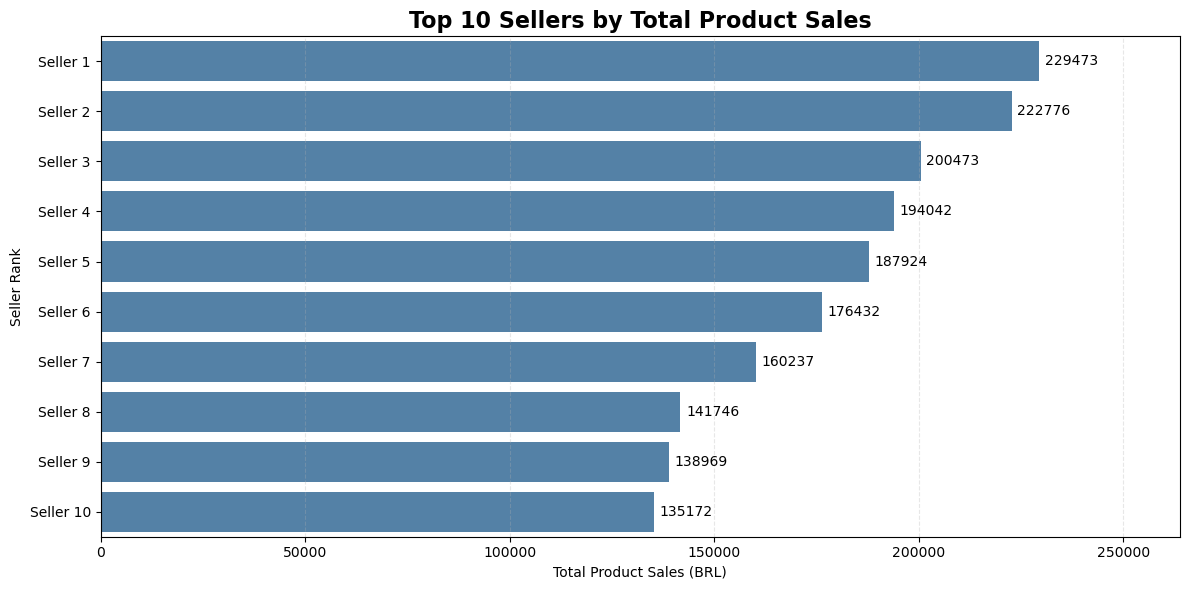

In [ ]:
# Visualization: Top 10 Sellers by Sales

top_10_sellers = df_sellers.head(10).copy()

# Create short labels for visualization
top_10_sellers["Seller Label"] = (
    "Seller " + top_10_sellers["Seller Rank"].astype(str)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=top_10_sellers,
    x="Total Sales",
    y="Seller Label",
    color="steelblue"
)

plt.title(
    "Top 10 Sellers by Total Product Sales",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Total Product Sales (BRL)")
plt.ylabel("Seller Rank")

# Display sales values
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=4
    )

max_sales = top_10_sellers["Total Sales"].max()

plt.xlim(0, max_sales * 1.15)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

**Results:**

- Total Sellers Analyzed: 3,095
- Highest-Ranked Seller Sales: BRL 229,472.63
- Second-Ranked Seller Sales: BRL 222,776.05
- Third-Ranked Seller Sales: BRL 200,472.92

**Business Insights:**

- The highest-ranked seller generated BRL 229,472.63 in product sales from 1,156 units across 1,132 orders.
- The second-ranked seller generated BRL 222,776.05 from 410 units.
- The third-ranked seller sold 1,987 units but generated a lower total sales value than the top two sellers.
- Seller rankings based on sales value differ from rankings based on units sold.
- Product pricing and sales volume both influence total seller sales performance.

**Business Recommendations:**

- Analyze top-performing sellers to understand their product mix and sales patterns.
- Compare seller performance using multiple metrics, including sales value, units sold, and order volume.
- Investigate opportunities to support lower-performing sellers through improved product visibility and operational support.

**Methodology Note:**

Seller sales are calculated using order item prices, excluding freight charges. Sales value is not equivalent to seller profit.

### Q11. Calculate the Moving Average of Customer Order Values

**Objective:** Analyze changes in customer spending by calculating a three-order moving average for each customer.

**SQL Concepts:** JOIN, CTE, SUM(), AVG(), PARTITION BY, ORDER BY, Window Functions

**Business Relevance:** Moving averages help businesses understand purchasing patterns and changes in customer spending over time.

**Methodology:** Payment records are aggregated to obtain total payment value per order. Orders are linked to unique customers, and a rolling average is calculated using the current order and up to two previous orders.

In [ ]:
#  Moving Average of Customer Order Values

query = """
WITH order_payments AS (
    SELECT
        order_id,
        ROUND(SUM(payment_value), 2) AS order_value
    FROM payments
    GROUP BY order_id
),

customer_orders AS (
    SELECT
        c.customer_unique_id,
        o.order_id,
        o.order_purchase_timestamp,
        op.order_value

    FROM orders AS o

    JOIN customers AS c
        ON o.customer_id = c.customer_id

    JOIN order_payments AS op
        ON o.order_id = op.order_id
),

moving_averages AS (
    SELECT
        customer_unique_id,
        order_id,
        order_purchase_timestamp,
        order_value,

        ROUND(
            AVG(order_value) OVER (
                PARTITION BY customer_unique_id
                ORDER BY order_purchase_timestamp, order_id
                ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
            ),
            2
        ) AS moving_average

    FROM customer_orders
)

SELECT *
FROM moving_averages
ORDER BY customer_unique_id, order_purchase_timestamp
LIMIT 20;
"""

cur.execute(query)

data = cur.fetchall()

df_moving = pd.DataFrame(
    data,
    columns=[
        "Customer ID",
        "Order ID",
        "Purchase Date",
        "Order Value",
        "Moving Average"
    ]
)

display(df_moving)

,Customer ID,Order ID,Purchase Date,Order Value,Moving Average
0,0000366f3b9a7992bf8c76cfdf3221e2,e22acc9c116caa3f2b7121bbb380d08e,2018-05-10 10:56:27,141.90,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,3594e05a005ac4d06a72673270ef9ec9,2018-05-07 11:11:27,27.19,27.19
2,0000f46a3911fa3c0805444483337064,b33ec3b699337181488304f362a6b734,2017-03-10 21:05:03,86.22,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,41272756ecddd9a9ed0180413cc22fb6,2017-10-12 20:29:41,43.62,43.62
4,0004aac84e0df4da2b147fca70cf8255,d957021f1127559cd947b62533f484f7,2017-11-14 19:45:42,196.89,196.89
5,0004bd2a26a76fe21f786e4fbd80607f,3e470077b690ea3e3d501cffb5e0c499,2018-04-05 19:33:16,166.98,166.98
6,00050ab1314c0e55a6ca13cf7181fecf,d0028facea13f508e880202d7097a5a1,2018-04-20 12:57:23,35.38,35.38
7,00053a61a98854899e70ed204dd4bafe,44e608f2db00c74a1fe329de44416a4e,2018-02-28 11:15:41,419.18,419.18
8,0005e1862207bf6ccc02e4228effd9a0,ae76bef74b97bcb0b3e355e60d9a6f9c,2017-03-04 23:32:12,150.12,150.12
9,0005ef4cd20d2893f0d9fbd94d3c0d97,01b330808c5819a6a3cb79b72f0b8288,2018-03-12 15:22:12,129.76,129.76


In [ ]:
# Identify Repeat Customers

query = """
SELECT
    c.customer_unique_id,
    COUNT(DISTINCT o.order_id) AS total_orders

FROM customers AS c

JOIN orders AS o
    ON c.customer_id = o.customer_id

GROUP BY c.customer_unique_id

HAVING COUNT(DISTINCT o.order_id) > 1

ORDER BY total_orders DESC

LIMIT 10;
"""

cur.execute(query)

data = cur.fetchall()

df_repeat_customers = pd.DataFrame(
    data,
    columns=["Customer ID", "Total Orders"]
)

display(df_repeat_customers)

,Customer ID,Total Orders
0,8d50f5eadf50201ccdcedfb9e2ac8455,17
1,3e43e6105506432c953e165fb2acf44c,9
2,1b6c7548a2a1f9037c1fd3ddfed95f33,7
3,6469f99c1f9dfae7733b25662e7f1782,7
4,ca77025e7201e3b30c44b472ff346268,7
5,12f5d6e1cbf93dafd9dcc19095df0b3d,6
6,47c1a3033b8b77b3ab6e109eb4d5fdf3,6
7,63cfc61cee11cbe306bff5857d00bfe4,6
8,dc813062e0fc23409cd255f7f53c7074,6
9,de34b16117594161a6a89c50b289d35a,6


In [ ]:
#  Analyze Moving Average for a Repeat Customer

# Select customer with the highest number of orders
selected_customer = df_repeat_customers.iloc[0]["Customer ID"]

query = """
WITH order_payments AS (
    SELECT
        order_id,
        ROUND(SUM(payment_value), 2) AS order_value
    FROM payments
    GROUP BY order_id
),

customer_orders AS (
    SELECT
        c.customer_unique_id,
        o.order_id,
        o.order_purchase_timestamp,
        op.order_value

    FROM orders AS o

    JOIN customers AS c
        ON o.customer_id = c.customer_id

    JOIN order_payments AS op
        ON o.order_id = op.order_id

    WHERE c.customer_unique_id = %s
)

SELECT
    customer_unique_id,
    order_id,
    order_purchase_timestamp,
    order_value,

    ROUND(
        AVG(order_value) OVER (
            PARTITION BY customer_unique_id
            ORDER BY order_purchase_timestamp, order_id
            ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
        ),
        2
    ) AS moving_average

FROM customer_orders

ORDER BY order_purchase_timestamp, order_id;
"""

cur.execute(query, (selected_customer,))

data = cur.fetchall()

df_customer_moving = pd.DataFrame(
    data,
    columns=[
        "Customer ID",
        "Order ID",
        "Purchase Date",
        "Order Value",
        "Moving Average"
    ]
)

# Convert numeric columns
df_customer_moving["Order Value"] = pd.to_numeric(
    df_customer_moving["Order Value"]
)

df_customer_moving["Moving Average"] = pd.to_numeric(
    df_customer_moving["Moving Average"]
)

# Add order sequence
df_customer_moving["Order Number"] = (
    range(1, len(df_customer_moving) + 1)
)

display(df_customer_moving)

print("Total Orders Analyzed:", len(df_customer_moving))

,Customer ID,Order ID,Purchase Date,Order Value,Moving Average,Order Number
0,8d50f5eadf50201ccdcedfb9e2ac8455,5d848f3d93a493c1c8955e018240e7ca,2017-05-15 23:30:03,22.77,22.77,1
1,8d50f5eadf50201ccdcedfb9e2ac8455,369634708db140c5d2c4e365882c443a,2017-06-18 22:56:48,51.75,37.26,2
2,8d50f5eadf50201ccdcedfb9e2ac8455,5837a2c844decae8a778657425f6d664,2017-07-17 22:11:13,25.59,33.37,3
3,8d50f5eadf50201ccdcedfb9e2ac8455,4f62d593acae92cea3c5662c76122478,2017-07-18 23:10:58,21.77,33.04,4
4,8d50f5eadf50201ccdcedfb9e2ac8455,bf92c69b7cc70f7fc2c37de43e366173,2017-07-24 22:11:50,166.71,71.36,5
5,8d50f5eadf50201ccdcedfb9e2ac8455,519203404f6116d406a970763ee75799,2017-08-05 08:59:43,81.89,90.12,6
6,8d50f5eadf50201ccdcedfb9e2ac8455,e3071b7624445af6e4f3a1b23718667d,2017-09-05 22:14:52,51.75,100.12,7
7,8d50f5eadf50201ccdcedfb9e2ac8455,cd4b336a02aacabd0ef22f6db711f95e,2017-10-18 23:25:04,37.77,57.14,8
8,8d50f5eadf50201ccdcedfb9e2ac8455,89d9b111d2b990deb5f5f9769f92800b,2017-10-29 16:58:02,21.77,37.10,9
9,8d50f5eadf50201ccdcedfb9e2ac8455,b850a16d8faf65a74c51287ef34379ce,2017-11-22 20:01:53,21.77,27.10,10


Total Orders Analyzed: 17


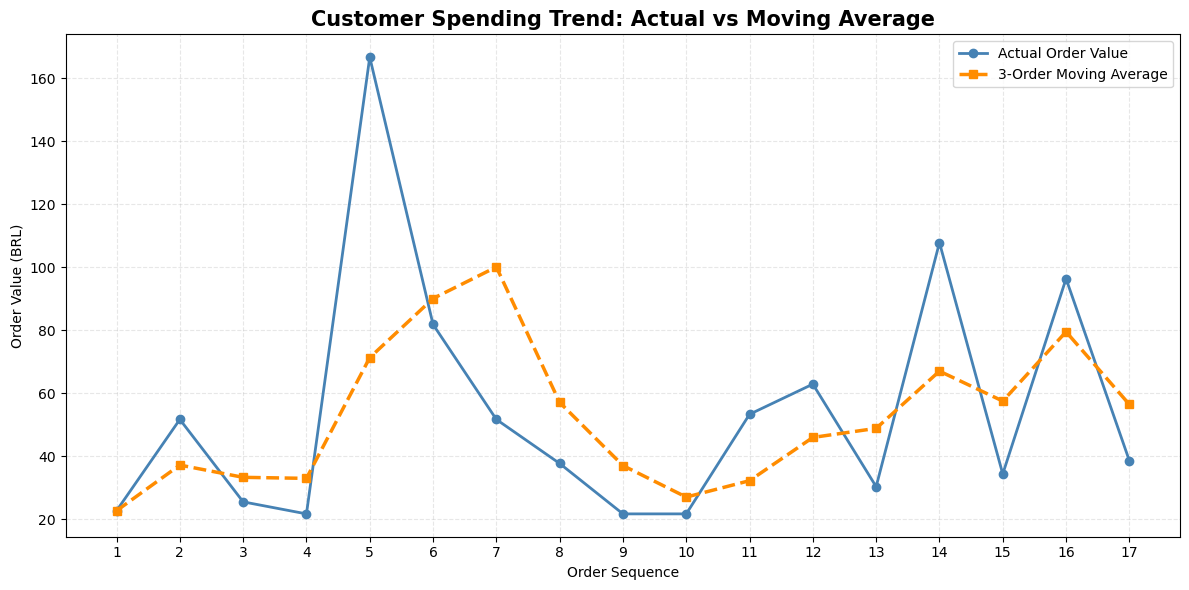

In [ ]:
# Visualization: Customer Order Value vs Moving Average

plt.figure(figsize=(12, 6))

# Actual order values
plt.plot(
    df_customer_moving["Order Number"],
    df_customer_moving["Order Value"],
    marker="o",
    linewidth=2,
    label="Actual Order Value",
    color="steelblue"
)

# Moving average
plt.plot(
    df_customer_moving["Order Number"],
    df_customer_moving["Moving Average"],
    marker="s",
    linewidth=2.5,
    linestyle="--",
    label="3-Order Moving Average",
    color="darkorange"
)

plt.title(
    "Customer Spending Trend: Actual vs Moving Average",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Order Sequence")
plt.ylabel("Order Value (BRL)")

plt.xticks(df_customer_moving["Order Number"])

plt.legend()

plt.grid(
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

**Result:** A selected repeat customer had 17 recorded orders.
The three-order moving average smooths individual spending spikes.

**Interpretation:** This is an illustrative single-customer series, not the
average trend of all customers. The average is calculated using the current
order and up to two preceding orders; it cannot explain why spending changes.


### Q12. Calculate Cumulative Monthly Sales Across Years

**Objective:** Analyze cumulative payment value over time to understand overall transaction growth.

**SQL Concepts:** JOIN, CTE, SUM(), YEAR(), MONTH(), GROUP BY, Window Functions

**Business Relevance:** Cumulative sales analysis helps businesses track growth over time and compare overall transaction performance across different periods.

**Methodology:** Payment records are first aggregated at the order level. Monthly payment totals are then calculated using order purchase dates, followed by a cumulative running total across all available months.

In [ ]:
#  Cumulative Monthly Sales

query = """
WITH order_payments AS (
    SELECT
        order_id,
        SUM(payment_value) AS order_value
    FROM payments
    GROUP BY order_id
),

monthly_sales AS (
    SELECT
        YEAR(o.order_purchase_timestamp) AS sales_year,
        MONTH(o.order_purchase_timestamp) AS sales_month,
        ROUND(SUM(op.order_value), 2) AS monthly_sales

    FROM orders AS o

    JOIN order_payments AS op
        ON o.order_id = op.order_id

    GROUP BY
        YEAR(o.order_purchase_timestamp),
        MONTH(o.order_purchase_timestamp)
)

SELECT
    sales_year,
    sales_month,
    monthly_sales,

    ROUND(
        SUM(monthly_sales) OVER (
            ORDER BY sales_year, sales_month
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ),
        2
    ) AS cumulative_sales

FROM monthly_sales

ORDER BY sales_year, sales_month;
"""

cur.execute(query)

data = cur.fetchall()

df_cumulative = pd.DataFrame(
    data,
    columns=[
        "Year",
        "Month",
        "Monthly Sales",
        "Cumulative Sales"
    ]
)

# Convert numeric columns
df_cumulative["Monthly Sales"] = pd.to_numeric(
    df_cumulative["Monthly Sales"]
)

df_cumulative["Cumulative Sales"] = pd.to_numeric(
    df_cumulative["Cumulative Sales"]
)

# Create date column
df_cumulative["Date"] = pd.to_datetime(
    df_cumulative["Year"].astype(str) + "-" +
    df_cumulative["Month"].astype(str) + "-01"
)

display(df_cumulative)

,Year,Month,Monthly Sales,Cumulative Sales,Date
0,2016,9,252.24,252.24,2016-09-01
1,2016,10,59090.48,59342.72,2016-10-01
2,2016,12,19.62,59362.34,2016-12-01
3,2017,1,138488.04,197850.38,2017-01-01
4,2017,2,291908.01,489758.39,2017-02-01
5,2017,3,449863.60,939621.99,2017-03-01
6,2017,4,417788.03,1357410.02,2017-04-01
7,2017,5,592918.82,1950328.84,2017-05-01
8,2017,6,511276.38,2461605.22,2017-06-01
9,2017,7,592382.92,3053988.14,2017-07-01


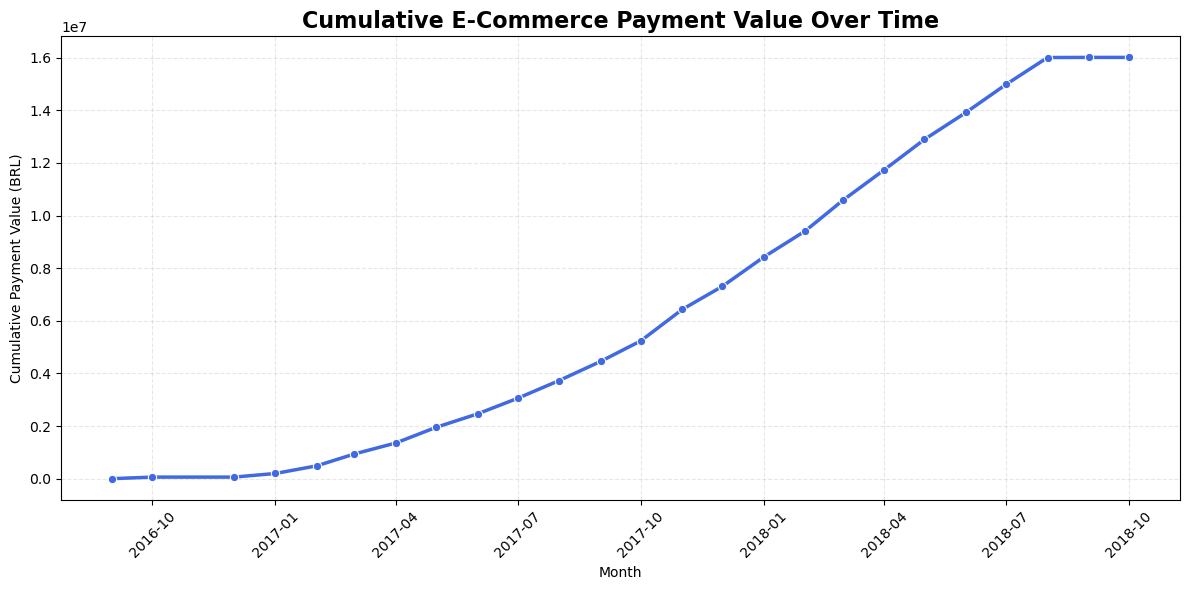

In [ ]:
# Visualization: Cumulative Sales Growth

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_cumulative,
    x="Date",
    y="Cumulative Sales",
    marker="o",
    linewidth=2.5,
    color="royalblue"
)

plt.title(
    "Cumulative E-Commerce Payment Value Over Time",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Cumulative Payment Value (BRL)")

plt.xticks(rotation=45)

plt.grid(
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

**Results:**

- Cumulative recorded payment value increased substantially throughout the observed period.
- The most substantial increases occurred during 2017 and the first eight months of 2018.
- The cumulative total approached BRL 16 million by the end of the available period.

**Business Insights:**

- The cumulative payment value demonstrates the accumulation of customer payments over time.
- The dataset recorded substantial transaction activity during 2017 and January–August 2018.
- The cumulative curve flattened during September and October 2018, reflecting unusually low recorded order volumes in those months.
- Cumulative totals alone cannot establish whether the underlying monthly growth rate is increasing.

**Business Recommendations:**

- Monitor monthly payment values alongside cumulative totals.
- Compare equivalent periods across years to evaluate business growth.
- Investigate the dataset's coverage limitations before interpreting unusually low activity in later months.

**Limitations:**

- Cumulative payment value is not equivalent to net profit.
- Payments may include freight and other order-related charges.
- The available data does not establish complete coverage for all calendar months.

### Q13. Calculate Year-over-Year Growth in Payment Value

**Objective:** Measure the percentage change in recorded payment value between comparable periods in 2017 and 2018.

**SQL Concepts:** JOIN, CTE, SUM(), YEAR(), MONTH(), LAG(), Window Functions

**Business Relevance:** Year-over-year growth analysis helps businesses evaluate changes in transaction performance over time.

**Methodology:** Payment values from January through August 2017 are compared with the same months in 2018. The LAG() window function is used to retrieve the previous year's payment value and calculate the percentage change.

In [ ]:
#  Year-over-Year Growth (January–August)

query = """
WITH order_payments AS (
    SELECT
        order_id,
        SUM(payment_value) AS order_value
    FROM payments
    GROUP BY order_id
),

yearly_sales AS (
    SELECT
        YEAR(o.order_purchase_timestamp) AS sales_year,
        ROUND(SUM(op.order_value), 2) AS total_sales

    FROM orders AS o

    JOIN order_payments AS op
        ON o.order_id = op.order_id

    WHERE
        YEAR(o.order_purchase_timestamp) IN (2017, 2018)
        AND MONTH(o.order_purchase_timestamp) BETWEEN 1 AND 8

    GROUP BY YEAR(o.order_purchase_timestamp)
),

sales_comparison AS (
    SELECT
        sales_year,
        total_sales,

        LAG(total_sales) OVER (
            ORDER BY sales_year
        ) AS previous_year_sales

    FROM yearly_sales
)

SELECT
    sales_year,
    total_sales,
    previous_year_sales,

    ROUND(
        (total_sales - previous_year_sales)
        * 100.0
        / NULLIF(previous_year_sales, 0),
        2
    ) AS yoy_growth_percentage

FROM sales_comparison

ORDER BY sales_year;
"""

cur.execute(query)

data = cur.fetchall()

df_yoy = pd.DataFrame(
    data,
    columns=[
        "Year",
        "Total Sales",
        "Previous Year Sales",
        "YoY Growth (%)"
    ]
)

# Convert numeric columns
for col in ["Total Sales", "Previous Year Sales", "YoY Growth (%)"]:
    df_yoy[col] = pd.to_numeric(df_yoy[col])

display(df_yoy)

,Year,Total Sales,Previous Year Sales,YoY Growth (%)
0,2017,3669022.12,NaN,NaN
1,2018,8694733.84,3669022.12,136.98


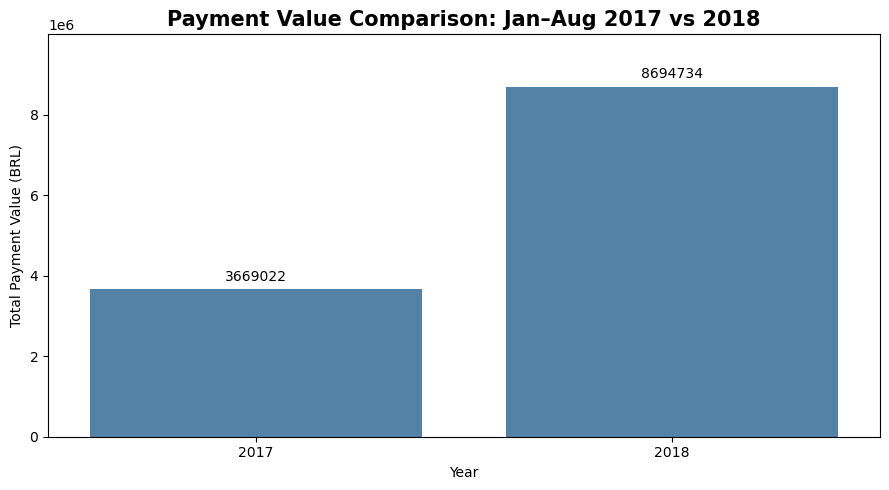

In [ ]:
# Visualization: Payment Value Comparison

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=df_yoy,
    x="Year",
    y="Total Sales",
    color="steelblue"
)

plt.title(
    "Payment Value Comparison: Jan–Aug 2017 vs 2018",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Total Payment Value (BRL)")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=4
    )

plt.ylim(0, df_yoy["Total Sales"].max() * 1.15)

plt.tight_layout()

plt.show()

**Results:**

- January–August 2017 Payment Value: BRL 3,669,022.12
- January–August 2018 Payment Value: BRL 8,694,733.84
- Year-over-Year Growth: 136.98%

**Business Insights:**

- Recorded payment value increased by approximately 136.98% between January–August 2017 and the corresponding period in 2018.
- The substantial increase indicates strong growth in recorded transaction value.
- The comparison uses equivalent calendar months to reduce distortions from the incomplete later months of 2018.

**Business Recommendations:**

- Investigate whether the growth was driven by higher order volumes, increased average order values, or both.
- Analyze product categories and geographical regions contributing most to the increase.
- Evaluate operational capacity to support continued transaction growth.

**Limitations:**

- Payment value is not equivalent to net profit.
- This comparison covers January–August rather than complete calendar years.
- The analysis assumes that data coverage is sufficiently comparable between the selected periods.

### Q14. Calculate the Six-Month Customer Retention Rate

**Objective:** Calculate the percentage of customers who placed another order within six months of their first purchase.

**SQL Concepts:** JOIN, CTE, MIN(), MAX(), CASE WHEN, DATE_ADD(), GROUP BY

**Business Relevance:** Customer retention analysis helps businesses understand repeat purchasing behavior and evaluate customer loyalty.

**Methodology:** Customers are identified using customer_unique_id. Each customer's first purchase date is determined, and subsequent purchases within six months are identified.

**Observation Window:** Only customers whose first recorded purchase occurred before March 1, 2018 are included, allowing a six-month follow-up period within the January–August 2018 analysis window.

In [ ]:
#  Six-Month Customer Retention Rate

query = """
WITH first_purchases AS (
    SELECT
        c.customer_unique_id,
        MIN(o.order_purchase_timestamp) AS first_purchase

    FROM customers AS c

    JOIN orders AS o
        ON c.customer_id = o.customer_id

    GROUP BY c.customer_unique_id
),

repeat_purchase_flags AS (
    SELECT
        fp.customer_unique_id,

        MAX(
            CASE
                WHEN o.order_purchase_timestamp > fp.first_purchase
                 AND o.order_purchase_timestamp <= DATE_ADD(
                     fp.first_purchase,
                     INTERVAL 6 MONTH
                 )
                THEN 1
                ELSE 0
            END
        ) AS repeated_within_6_months

    FROM first_purchases AS fp

    JOIN customers AS c
        ON fp.customer_unique_id = c.customer_unique_id

    JOIN orders AS o
        ON c.customer_id = o.customer_id

    WHERE fp.first_purchase < '2018-03-01'

    GROUP BY fp.customer_unique_id
)

SELECT
    COUNT(*) AS eligible_customers,

    COALESCE(
        SUM(repeated_within_6_months),
        0
    ) AS retained_customers,

    ROUND(
        COALESCE(SUM(repeated_within_6_months), 0)
        * 100.0 /
        NULLIF(COUNT(*), 0),
        2
    ) AS retention_rate

FROM repeat_purchase_flags;
"""

cur.execute(query)

data = cur.fetchone()

eligible_customers = data[0]
retained_customers = data[1]
retention_rate = data[2]

print(f"Eligible Customers: {eligible_customers:,}")
print(f"Retained Customers: {retained_customers:,}")
print(f"Six-Month Retention Rate: {retention_rate}%")

Eligible Customers: 57,510
Retained Customers: 1,657
Six-Month Retention Rate: 2.88%


**Results:**

- Eligible Customers: 57,510
- Customers Making Another Purchase Within Six Months: 1,657
- Six-Month Customer Retention Rate: 2.88%

**Business Insights:**

- Approximately 2.88% of eligible customers placed another recorded order within six months of their first purchase.
- Repeat purchasing within the defined six-month observation period was relatively uncommon.
- The result suggests an opportunity to investigate customer purchasing frequency and retention patterns.

**Business Recommendations:**

- Analyze repeat purchasing behavior across product categories and customer segments.
- Investigate whether targeted loyalty programs or personalized promotions could encourage repeat purchases.
- Examine customer satisfaction, delivery performance, and purchasing frequency before selecting retention strategies.

**Limitations:**

- The metric is based on recorded orders rather than confirmed customer satisfaction.
- Customers whose first purchase occurred on or after March 1, 2018 were excluded to provide a more consistent observation window.
- Data coverage and the nature of purchased products may affect repeat purchasing patterns.
- The retention metric does not establish the causes of low repeat purchasing.

### Q15. Identify the Top 3 Customers by Spending in Each Year

**Objective:** Identify the three highest-spending customers for each year in the available dataset.

**SQL Concepts:** JOIN, SUM(), GROUP BY, CTE, ROW_NUMBER(), PARTITION BY, ORDER BY

**Business Relevance:** Identifying high-value customers helps businesses understand customer spending concentration and explore customer relationship management opportunities.

**Methodology:** Payment records are aggregated at the order level. Orders are linked to individual customers using customer_unique_id. Annual spending is calculated for each customer, and customers are ranked within each year.

**Ranking Method:** ROW_NUMBER() is used to select exactly three customers per year, with customer ID used to break spending ties consistently.

In [ ]:
#  Top 3 Customers by Spending in Each Year

query = """
WITH order_payments AS (
    SELECT
        order_id,
        SUM(payment_value) AS order_value
    FROM payments
    GROUP BY order_id
),

customer_yearly_spending AS (
    SELECT
        YEAR(o.order_purchase_timestamp) AS purchase_year,
        c.customer_unique_id,
        ROUND(SUM(op.order_value), 2) AS total_spending

    FROM orders AS o

    JOIN customers AS c
        ON o.customer_id = c.customer_id

    JOIN order_payments AS op
        ON o.order_id = op.order_id

    GROUP BY
        YEAR(o.order_purchase_timestamp),
        c.customer_unique_id
),

ranked_customers AS (
    SELECT
        purchase_year,
        customer_unique_id,
        total_spending,

        ROW_NUMBER() OVER (
            PARTITION BY purchase_year
            ORDER BY total_spending DESC, customer_unique_id
        ) AS customer_rank

    FROM customer_yearly_spending
)

SELECT
    purchase_year,
    customer_unique_id,
    total_spending,
    customer_rank

FROM ranked_customers

WHERE customer_rank <= 3

ORDER BY purchase_year, customer_rank;
"""

cur.execute(query)

data = cur.fetchall()

df_top_customers = pd.DataFrame(
    data,
    columns=[
        "Year",
        "Customer ID",
        "Total Spending",
        "Customer Rank"
    ]
)

# Convert numeric column
df_top_customers["Total Spending"] = pd.to_numeric(
    df_top_customers["Total Spending"]
)

display(df_top_customers)

,Year,Customer ID,Total Spending,Customer Rank
0,2016,fdaa290acb9eeacb66fa7f979baa6803,1423.55,1
1,2016,753bc5d6efa9e49a03e34cf521a9e124,1400.74,2
2,2016,b92a2e5e8a6eabcc80882c7d68b2c70b,1227.78,3
3,2017,0a0a92112bd4c708ca5fde585afaa872,13664.08,1
4,2017,da122df9eeddfedc1dc1f5349a1a690c,7571.63,2
5,2017,dc4802a71eae9be1dd28f5d788ceb526,6929.31,3
6,2018,46450c74a0d8c5ca9395da1daac6c120,9553.02,1
7,2018,763c8b1c9c68a0229c42c9fc6f662b93,7274.88,2
8,2018,459bef486812aa25204be022145caa62,6922.21,3


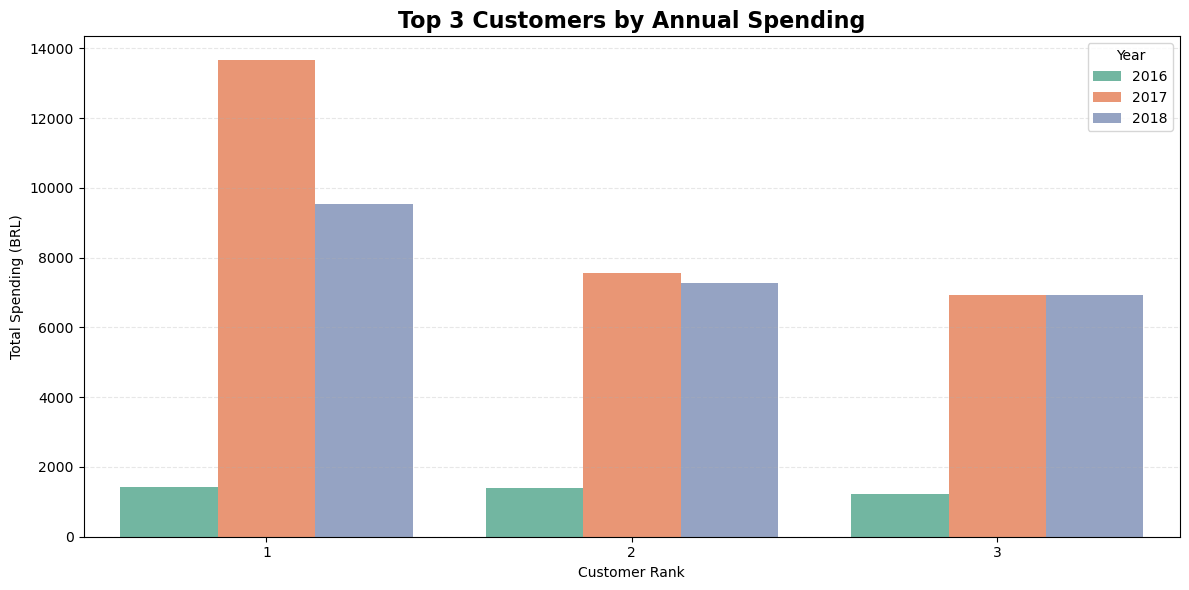

In [ ]:
# Visualization: Top 3 Customers by Year

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=df_top_customers,
    x="Customer Rank",
    y="Total Spending",
    hue="Year",
    palette="Set2"
)

plt.title(
    "Top 3 Customers by Annual Spending",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Customer Rank")
plt.ylabel("Total Spending (BRL)")

plt.legend(title="Year")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

**Results:**

Highest customer spending in each recorded year:

- 2016: BRL 1,423.55
- 2017: BRL 13,664.08
- 2018: BRL 9,553.02

**Business Insights:**

- The highest-spending customer in 2017 spent BRL 13,664.08.
- The highest individual spending recorded in 2018 was BRL 9,553.02.
- The top three customers in each year contributed significantly different spending amounts.
- Customer spending patterns vary across years.

**Business Recommendations:**

- Investigate purchasing patterns among high-value customers.
- Explore customer segmentation based on spending and purchase frequency.
- Consider targeted engagement strategies for high-value repeat customers.

**Limitations:**

- The analysis identifies the highest-spending customers within the available records.
- The dataset has incomplete coverage in 2016 and late 2018.
- Customer spending rankings alone do not establish profitability or long-term customer loyalty.
- The ranking should not be used to infer overall year-over-year customer spending trends.

## 3. Executive Summary

This project combined SQL, Pandas, and visualizations to explore customer
distribution, product/category sales, payments, repeat purchasing, and seller
performance across seven Brazilian e-commerce tables.

| Finding | Verified result | Interpretation |
|---|---:|---|
| Distinct customer cities | 4,119 | Broad recorded geographic coverage |
| Orders placed in 2017 | 45,101 | Historical order-volume benchmark |
| Most valuable item-sales category | Health Beauty, R$1,258,681.34 | 9.26% of item sales |
| Orders paid in multiple installments | 51.46% | Counted once per order with payment records |
| Pearson price/frequency correlation | -0.0321 | Negligible linear association |
| Highest seller item sales | R$229,472.63 | Not equivalent to profit |
| Jan–Aug payment growth, 2017 vs 2018 | +136.98% | Comparable calendar periods only |
| Six-month repeat purchase rate | 2.88% | Among 57,510 eligible first-time customers |

### Actionable considerations

1. Examine customer demand and product margins before increasing inventory
   in high-sales categories.
2. Compare seller unit counts, order counts, sales, and costs rather than
   relying on one ranking.
3. Segment repeat buyers and investigate whether product categories and
   delivery experience influence their return behavior.
4. Use monthly order and payment value trends alongside cumulative totals;
   never interpret late-2018 sparse records as proof of a business collapse.

### Important limitations

- The source table schema is inferred from CSVs; dates are stored as `TEXT`
  and monetary values as floating-point numbers in the original database.
- Some payment and product metadata records are unusual or missing.
- Category item sales and payment value use different definitions and should
  not be presented as identical revenue measures.
- Results are observational; they do not establish causal effects or profit.
- Counts and charts reflect the provided snapshot, not live commerce data.

## 4. Reproduction and next improvements

Use `requirements.txt`, create the MySQL database using the separate guarded
import script **only if your tables do not already contain data**, and run
the cells from top to bottom. The quality audit can be run independently in
`01_Data_Quality_Audit.ipynb`. A recommended follow-up is a separate typed
analytical database with `DATETIME`, `DECIMAL`, indices, and appropriate
primary/foreign keys, once conversions have been verified.

**Prepared as a portfolio case study.**
